In [212]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt


In [213]:
df = pd.read_csv('economic_index.csv')

In [214]:
df.head()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


In [215]:
#remove label from df which is first index
df.drop(columns=['Unnamed: 0', 'month', 'year'], inplace=True)


In [216]:
df.head()

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256


In [217]:
df.isnull().sum()

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

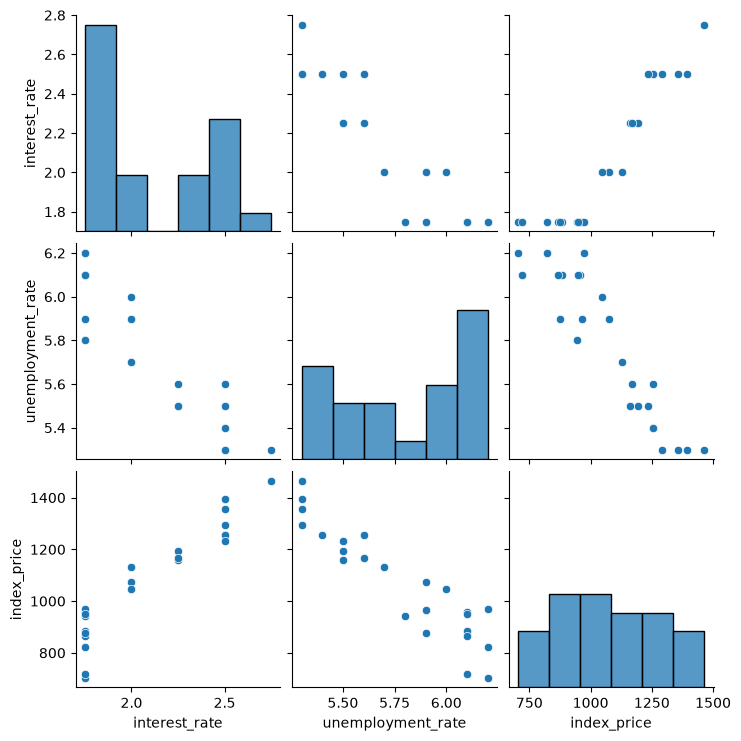

In [218]:
import seaborn as sn
sn.pairplot(df)


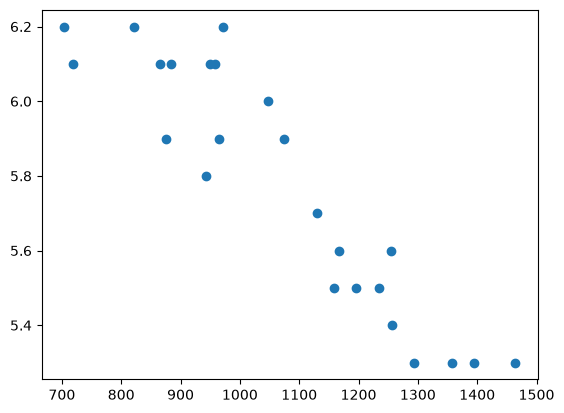

In [219]:
plt.scatter(df['index_price'], df['unemployment_rate'])

In [220]:
X= df.iloc[:,:-1]
y = df.iloc[:,-1]

In [221]:
y

0     1464
1     1394
2     1357
3     1293
4     1256
5     1254
6     1234
7     1195
8     1159
9     1167
10    1130
11    1075
12    1047
13     965
14     943
15     958
16     971
17     949
18     884
19     866
20     876
21     822
22     704
23     719
Name: index_price, dtype: int64

In [222]:
#train test split
from sklearn.model_selection import train_test_split
X_train , X_test, y_train, y_test= train_test_split(X,y,test_size=0.25, random_state=42)

<Axes: xlabel='interest_rate', ylabel='unemployment_rate'>

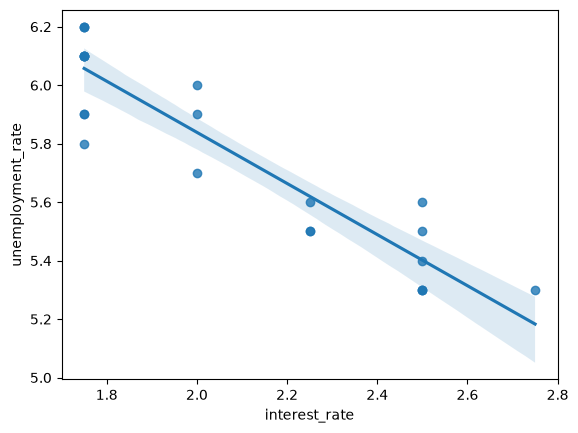

In [223]:
#regplot between x and y
import seaborn as sn
sn.regplot(x=df['interest_rate'], y=df['unemployment_rate'])

In [224]:
#Standardize the data
from sklearn.preprocessing import StandardScaler
# 1. Instantiate the scaler (create the object)
scaler = StandardScaler()

# 2. Fit and transform your training data
X_train = scaler.fit_transform(X_train)
X_train

array([[-0.90115511,  0.37908503],
       [ 1.31077107, -1.48187786],
       [-0.90115511,  1.30956648],
       [ 1.31077107, -0.55139641],
       [ 1.31077107, -1.48187786],
       [-0.16384638,  0.68924552],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -1.48187786],
       [ 1.31077107, -1.17171738],
       [-0.90115511,  1.30956648],
       [-0.90115511,  0.999406  ],
       [-0.90115511,  0.37908503],
       [-0.90115511,  0.999406  ],
       [ 0.57346234, -0.8615569 ],
       [-0.16384638, -0.24123593],
       [-0.90115511,  0.06892455],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -0.8615569 ]])

In [225]:

# 2. Fit and transform your training data
X_test = scaler.transform(X_test)


In [226]:
#Multi linear regression 
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
lm= LinearRegression()
model= lm.fit(X_train,y_train)
model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 88.27,-116.26]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1053
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[5.87,1.23]"


In [227]:
# model = sm.OLS(y_train, X_train).fit()
# print(model.summary)

In [228]:
#cross-validation 
from  sklearn.model_selection import cross_val_score
val_score =  cross_val_score(lm, X_train, y_train, scoring= 'neg_mean_squared_error' ,  cv=3)

In [229]:
np.mean(val_score)

np.float64(-5914.8281801623925)

In [230]:
#predictions  
y_pred = lm.predict(X_test)

In [231]:
y_pred

array([1204.22770398,  821.65051903, 1406.51300368,  857.70889608,
        994.90992298, 1168.16932693])

In [232]:
#Performance matrix
from sklearn.metrics import mean_squared_error, mean_absolute_error
mse=mean_squared_error(y_test, y_pred)
print("Mean Squared Error :", mse)
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error :", mae)
rmse = np.sqrt(mse)
print("Root Mean Squared Error :", rmse)

Mean Squared Error : 5793.7628877125835
Mean Absolute Error : 59.9357815232356
Root Mean Squared Error : 76.11677139574815


In [233]:
from sklearn.metrics import r2_score
score = r2_score(y_test, y_pred)
print(score)
adj_score = 1- (1-score)*(len(y_test)-1)/(len(y_test)-X_train.shape[1]-1)
print(adj_score)

0.8278978091457141
0.7131630152428567
